# 01 Data preparation and proxy leakage ("before")

**Goal:** show the fixed 70/15/15 split (stratified on TARGET x gender) and measure how well gender can be predicted from the features alone, even though gender is not a feature.
Results are loaded from `artifacts/`; nothing is trained here.

In [1]:
import json, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt
from src.utils import load_config, resolve

cfg = load_config('configs/data.yaml')
prep = json.loads((resolve(cfg['paths']['prep_artifacts']) / 'prep_report.json').read_text())
before = json.loads((resolve(cfg['paths']['leakage_artifacts']) / 'before.json').read_text())
print('XNA gender rows dropped:', prep['xna_dropped'], '| rows kept:', prep['n_rows'])

XNA gender rows dropped: 4 | rows kept: 307507


## Split table

In [2]:
split = pd.DataFrame(prep['splits']).T
split['default_rate_%'] = (split['default_rate'] * 100).round(2)
split['female_%'] = (split['pct_female'] * 100).round(2)
split[['rows', 'default_rate_%', 'female_%']].astype({'rows': int})

,rows,default_rate_%,female_%
train,215254,8.07,65.84
val,46126,8.07,65.83
test,46127,8.07,65.84


In [3]:
dg = prep['default_rate_by_gender']
pd.Series({'F': f"{dg['F']*100:.2f}%", 'M': f"{dg['M']*100:.2f}%"}, name='default rate by gender')

F     7.00%
M    10.14%
Name: default rate by gender, dtype: str

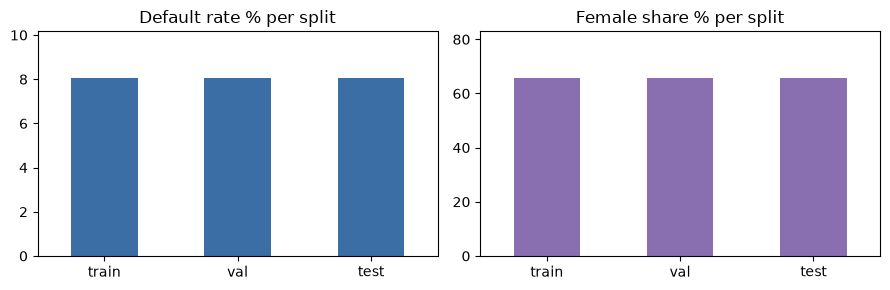

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
split['default_rate_%'].plot.bar(ax=ax[0], color='#3b6ea5', title='Default rate % per split')
split['female_%'].plot.bar(ax=ax[1], color='#8a6fb0', title='Female share % per split')
for a in ax: a.set_ylim(0, a.get_ylim()[1] * 1.2); a.tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

## Gender predicted from features only (TARGET never used)

In [5]:
aucs = pd.DataFrame({
    'val AUC': [before['lightgbm']['val_auc'], before['logistic']['val_auc'], before['shuffled_control']['val_auc']],
    'test AUC': [before['lightgbm']['test_auc'], before['logistic']['test_auc'], before['shuffled_control']['test_auc']],
}, index=['LightGBM probe', 'Logistic probe', 'Shuffled-gender control']).round(4)
print('Soft flag (premise weak, AUC < 0.60):', before['soft_flag_premise_weak'])
print('Shuffled control within 0.5 +/- 0.02:', before['shuffled_control']['within_tolerance'])
aucs

Soft flag (premise weak, AUC < 0.60): False
Shuffled control within 0.5 +/- 0.02: True


,val AUC,test AUC
LightGBM probe,0.8991,0.9003
Logistic probe,0.8745,0.8769
Shuffled-gender control,0.5037,0.5030


## Top-15 proxy features (LightGBM gain)

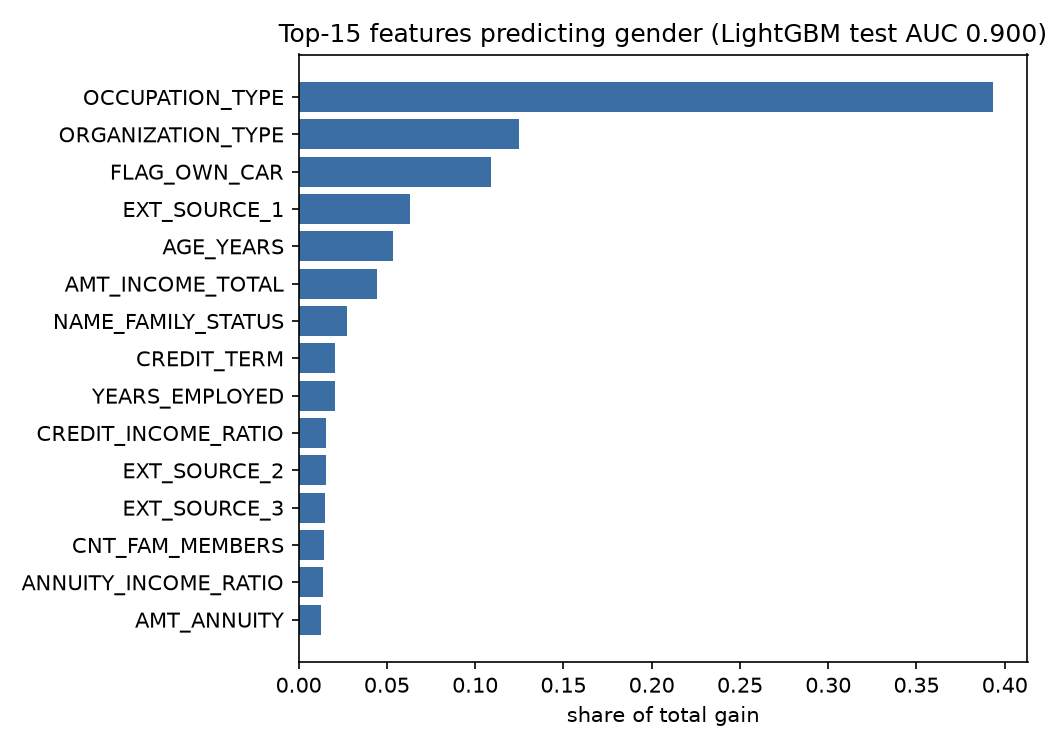

In [6]:
from IPython.display import Image
Image(str(resolve(cfg['paths']['leakage_artifacts']) / 'top15_proxy_features_before.png'))

In [7]:
pd.DataFrame(before['top_features']).assign(gain_share=lambda d: d.gain_share.round(4)).set_index('feature')

,gain_share
feature,
OCCUPATION_TYPE,0.3932
ORGANIZATION_TYPE,0.1250
FLAG_OWN_CAR,0.1090
EXT_SOURCE_1,0.0634
AGE_YEARS,0.0537
AMT_INCOME_TOTAL,0.0442
NAME_FAMILY_STATUS,0.0274
CREDIT_TERM,0.0206
YEARS_EMPLOYED,0.0206


## What this shows

- The split is stable: default rate and female share match across train/val/test to well under 0.5 percentage points, and every TARGET x gender cell is large.
- Gender is excluded from X, yet a gradient-boosted probe recovers it from the remaining features with a high AUC. Features such as occupation, organisation and car ownership act as proxies, so dropping the column does not remove gender information.
- The shuffled-label control sits at 0.5, so the high AUC is real signal and not a pipeline artefact.
- This is the "before" number. Phase 6 probes the learned representation z to see whether the adversarial term reduces it.